# EEG Decoding Workshop ① — CSP + Machine Learning (Classical Approach)

In this notebook, we build a **decoder** that classifies "imagined left-hand movement"
vs. "imagined right-hand movement" from EEG signals recorded during **Motor Imagery (MI)**,
using classical machine learning models.



## Motor Imagery and EEG
- When you move (or imagine moving) your hand, the power of μ waves (8–13 Hz) and β waves
  (13–30 Hz) **decreases** in the contralateral **sensorimotor cortex** — a phenomenon
  called **ERD (Event-Related Desynchronization)**.
- Left-hand imagery → ERD in the right hemisphere; right-hand imagery → ERD in the left hemisphere.
  The basic idea of a decoder is to detect this **left–right asymmetry** with machine learning.
- Classical BCI uses C3/C4 (directly above the hand motor area), but the Emotiv EPOC X used
  here lacks C3/C4 electrodes, so we rely on **FC5 / FC6 / T7 / T8** which are closer to
  the sensorimotor cortex.

## Notebook Outline
1. Load the recorded data
2. Inspect preprocessed signals (bandpass + notch + CAR)
3. Visualize μ- and β-band ERD time courses
4. Learn a spatial filter with **CSP (Common Spatial Patterns)** to enhance the left–right contrast
5. Cross-validate with CSP + classifiers (LDA / SVM)
6. Improve accuracy by **narrowing the bandpass to the μ-band (8–13 Hz)**
7. Summary and exercises

> 💡 Preprocessing and epoch extraction are handled by `utils.py`, using the same
> pipeline as the real-time BCI system.

> 📍 **If you opened this in Google Colab, run the "Setup" cell below first.**

In [1]:
# === Setup (run first in Google Colab) ===
# Automatically skipped in local Jupyter environments.
import sys

if "google.colab" in sys.modules:
    !pip install -q mne
    from google.colab import drive
    drive.mount("/content/drive")
    # ↓ Change this path to match where you placed the notebooks folder in Drive
    %cd /content/drive/MyDrive/MotorImageryDemo/notebooks

In [2]:
# Required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from mne.decoding import CSP
mne.set_log_level("WARNING")

from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.svm import SVC
from sklearn.model_selection import (StratifiedKFold, cross_validate,
                                     cross_val_score, cross_val_predict)
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, cohen_kappa_score)

import utils as U   # data loading, preprocessing, epoching, and ERD helpers

plt.rcParams["figure.figsize"] = (9, 4)
np.random.seed(0)
print("Ready.")

Ready.


## 1. Load and preprocess the Data

We load recordings from 5 sessions. Each session contains 10 left-imagery trials and
10 right-imagery trials. The controls below configure the notch frequency, bandpass
range, and CAR (Common Average Reference). Inside `load_dataset()`, preprocessing is
applied to each session before the MI window (4 seconds) is extracted as one trial.

In [3]:
# === Data location ===
#   None        … auto-search (checks MI_DATA_DIR env var, then ../data)
#   "/path/..." … specify the folder containing recording.npz files directly
DATA_DIR = None

# === Preprocessing controls ===
# BANDPASS_HZ = (low, high): keep EEG frequencies between low and high Hz.
# Examples: (8.0, 30.0) for mu + beta, or (8.0, 13.0) for mu only.
BANDPASS_HZ = (8.0, 30.0)

# NOTCH_HZ: remove electrical mains noise at this frequency.
# Use 50.0 in Japan/Europe, 60.0 in North America, or None to disable it.
NOTCH_HZ = 50.0

# APPLY_CAR: True applies Common Average Reference across all EEG channels.
# Set it to False to keep the original channel references.
APPLY_CAR = True
REFERENCE = "car" if APPLY_CAR else "none"

In [4]:
ds = U.load_dataset(
    data_dir=DATA_DIR,
    bandpass=BANDPASS_HZ,
    notch_hz=NOTCH_HZ,
    reference=REFERENCE,
)
ds_original = ds  # preserve all trials so this notebook can safely reapply rejection
print(ds.summary())

# X: (n_trials, n_channels, n_samples), y: 0=left / 1=right
X, y, fs, ch_names = ds.X, ds.y, ds.fs, ds.ch_names
print("\nX shape:", X.shape, "| y shape:", y.shape, "| fs:", fs, "Hz")
print(f"Preprocessing: bandpass={BANDPASS_HZ} Hz, notch={NOTCH_HZ} Hz, CAR={APPLY_CAR}")

# CAR makes the 14 channels sum to zero, so the spatial covariance is
# rank-deficient (true rank = n_channels - 1). We pass this rank to CSP below;
# otherwise CSP's top component collapses onto the empty null direction
# (log-variance ≈ -64) and the feature-space scatter becomes unreadable.
CSP_RANK = {"eeg": X.shape[1] - 1} if APPLY_CAR else None

trials       : 100
channels     : 14  ['AF3', 'F7', 'F3', 'FC5', 'T7', 'P7', 'O1', 'O2', 'P8', 'T8', 'FC6', 'F4', 'F8', 'AF4']
samples/trial: 512  (4.0s @ 128Hz)
sessions     : 5
  [0] yamamura_session1_1_20260617T022949: {'left': 10, 'right': 10}
  [1] yamamura_session2_20260617T023244: {'left': 10, 'right': 10}
  [2] yamamura_session3_20260617T023642: {'left': 10, 'right': 10}
  [3] yamamura_session4_20260617T024042: {'left': 10, 'right': 10}
  [4] yamamura_session5_20260617T024325: {'left': 10, 'right': 10}
class totals : {'left': 50, 'right': 50}

X shape: (100, 14, 512) | y shape: (100,) | fs: 128.0 Hz
Preprocessing: bandpass=(8.0, 30.0) Hz, notch=50.0 Hz, CAR=True


## 2. Inspect Preprocessed Signals and Reject Bad Trials

The recording contains 14 EPOC X channels:
`AF3`, `F7`, `F3`, `FC5`, `T7`, `P7`, `O1`, `O2`, `P8`, `T8`, `FC6`, `F4`, `F8`, `AF4`.

The figure below helps connect the headset channel names with the approximate brain regions underneath.

| EPOC X channel locations | Motor cortex location |
|---|---|
| ![EPOC X channel placement](assets/epoc_channel_locations.png) | ![Motor cortex region](assets/motor_cortex_regions.png) |

_Source: channel location figure from [ResearchGate](https://www.researchgate.net/figure/Emotiv-EPOC-headset-14-channel-placement-with-two-reference-channels_fig2_309427804); motor cortex figure from [ResearchGate](https://www.researchgate.net/figure/Primary-brain-regions-Motor-cortex-is-the-region-in-charge-of-planning-control-and_fig2_331905251)._

For this quick plot, we show only a smaller candidate subset near the motor cortex.
The slow drift and power-line noise have been removed, leaving the μ/β-band oscillations.

Change `trial` in the code cell below and run it again to inspect different trials.
Compare several left- and right-imagery trials rather than drawing conclusions from only one.

**Motor-area candidate channels for plotting:**
- `FC5` / `FC6`: closest available frontal-central electrodes to the left/right hand motor areas.
- `T7` / `T8`: lateral electrodes that may still capture sensorimotor activity around the hand area.
- `F3` / `F4`: secondary frontal candidates; less ideal than C3/C4, but useful because EPOC X does not include C3/C4.

The other channels (`AF3`, `AF4`, `F7`, `F8`, `P7`, `P8`, `O1`, `O2`) are still present in `X` and are used later by the all-channel CSP baseline. They are just less directly targeted to hand motor imagery, so they are omitted from this first visual sanity check.

Showing original trial 0/99: right


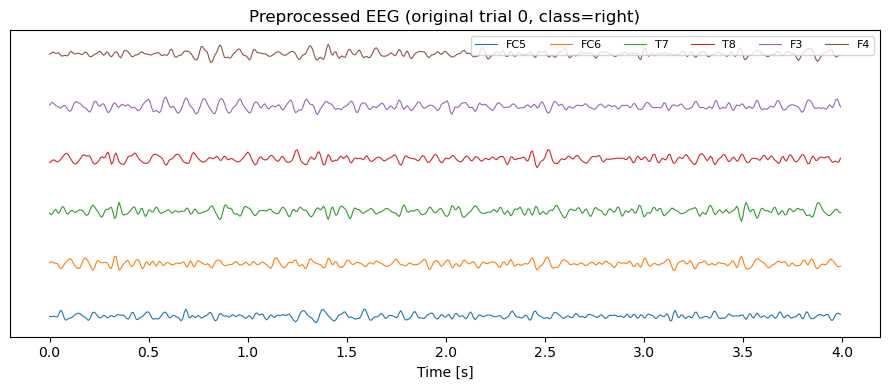

In [5]:
motor_ch = [c for c in ["FC5", "FC6", "T7", "T8", "F3", "F4"] if c in ch_names]
idx = [ch_names.index(c) for c in motor_ch]

# Always inspect the original, un-rejected trials so their indices stay stable.
X_inspect, y_inspect = ds_original.X, ds_original.y

# Try changing this value (0 to len(X_inspect) - 1) to inspect another MI trial.
trial = 0
print(f"Showing original trial {trial}/{len(X_inspect) - 1}: "
      f"{U.CLASS_NAMES[y_inspect[trial]]}")

t = np.arange(X_inspect.shape[2]) / fs
fig, ax = plt.subplots()
offset = 0
for c, i in zip(motor_ch, idx):
    ax.plot(t, X_inspect[trial, i] + offset, label=c, lw=0.8)
    offset += 60  # vertical offset for readability
ax.set(xlabel="Time [s]", yticks=[],
       title=f"Preprocessed EEG (original trial {trial}, "
             f"class={U.CLASS_NAMES[y_inspect[trial]]})")
ax.legend(loc="upper right", ncol=len(motor_ch), fontsize=8)
plt.tight_layout(); plt.show()

### Optional: Remove Bad Trials

After inspecting the plot above, list any trials containing large artifacts or flat/broken signals in `BAD_TRIALS`. The indices refer to the original loaded dataset. This removal is also applied to the cross-validation in Section 5 and to the Section 6 analysis.

In [6]:
# Set True to remove the listed trials from all analyses below.
REJECT_BAD_TRIALS = True
BAD_TRIALS = [1]  # Example: [7, 23]

removed_trials = sorted(set(BAD_TRIALS)) if REJECT_BAD_TRIALS else []
ds = U.remove_bad_trials(ds_original, removed_trials) if removed_trials else ds_original
X, y = ds.X, ds.y
print("Removed original trials:", removed_trials)
print("Remaining trials:", len(X))

Removed original trials: [1]
Remaining trials: 99


## 3. Visualize μ- and β-band ERD

ERD is a task-related decrease in rhythmic EEG power. We extract one continuous epoch around
MI onset: the **baseline/cue period (−3 to 0 s)** and the **MI period (0 to 4 s)**.
The first trial of each session is excluded because it is preceded by GET READY rather than
a normal baseline.

We calculate the time course separately for the **μ band (8–13 Hz)** and
**β band (13–30 Hz)**:

1. μ- or β-band filter
2. Hilbert amplitude squared (= power)
3. Average power across trials of the same MI class
4. Normalize by the mean baseline power $R$

$$\mathrm{ERD}\%(t) = \frac{A(t)-R}{R} \times 100$$

- $A(t)$: the band power at time $t$, averaged across trials of the same MI class
- $R$: the mean of $A(t)$ during the baseline period (−3 to 0 s)

A negative value is **ERD** (desynchronization); a positive value is **ERS**
(synchronization). EPOC X has no C3/C4 electrodes, so **FC5/FC6 are used as the nearest
left/right sensorimotor surrogates**. For left-hand MI, a stronger decrease is expected at
FC6; for right-hand MI, at FC5. The β plot shows ERD during MI; post-MI β rebound
cannot be assessed because the epoch ends at 4 s.

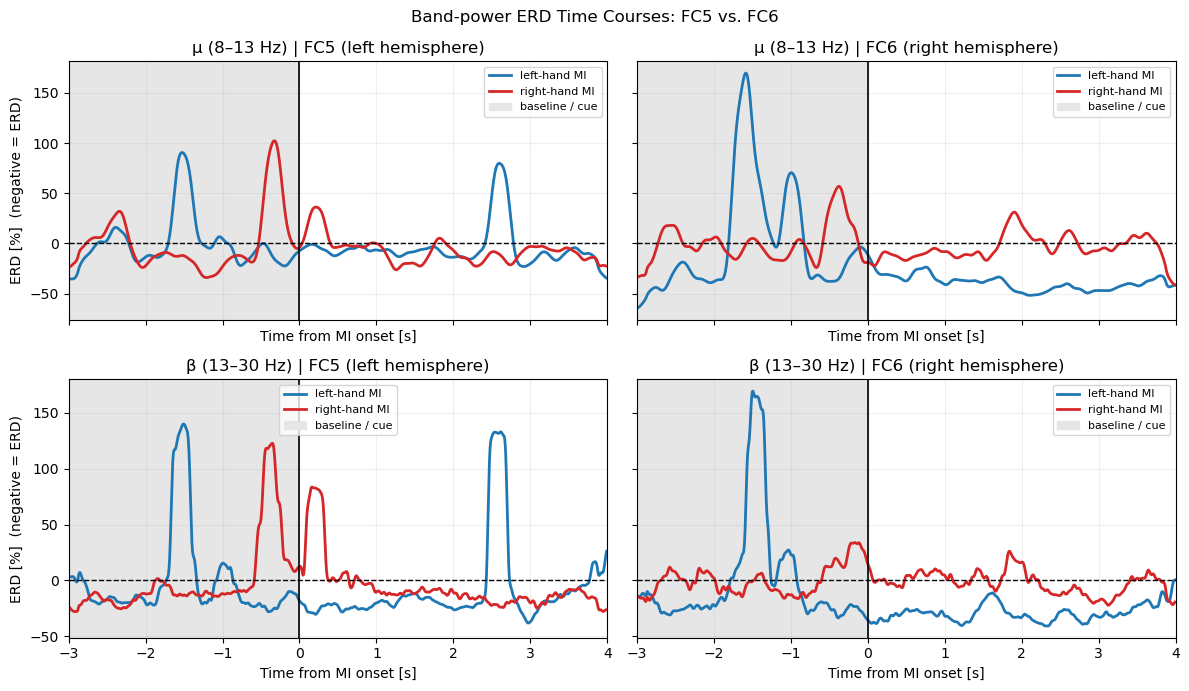

ERD analysis: 94 trials; baseline=(-3.0, 0.0) s, MI=(0.0, 4.0) s


In [7]:
BASELINE_S = (-3.0, 0.0)
MI_S = (0.0, 4.0)
ERD_BANDS = {"μ (8–13 Hz)": (8.0, 13.0), "β (13–30 Hz)": (13.0, 30.0)}
SKIP_FIRST_TRIAL_PER_SESSION = True


erd_result = U.load_erd_time_courses(
    data_dir=DATA_DIR, bandpass=BANDPASS_HZ, notch_hz=NOTCH_HZ,
    reference=REFERENCE, baseline_window_s=BASELINE_S, mi_window_s=MI_S,
    bands=ERD_BANDS, excluded_trials=removed_trials,
    skip_first_trial_per_session=SKIP_FIRST_TRIAL_PER_SESSION,
)
U.plot_erd_time_courses(erd_result)
plt.show()
print(f"ERD analysis: {erd_result.n_trials} trials; "
      f"baseline={BASELINE_S} s, MI={MI_S} s")

## 4. CSP (Common Spatial Patterns)

CSP learns a spatial filter — a weighted combination of channels — such that the
**variance is maximized for one class and minimized for the other**. Since the variance
of a bandpass-filtered signal equals the power in that band, CSP produces "composite
channels" with the greatest power difference between left and right imagery.

We first train CSP on the full dataset for visualization, and draw the spatial patterns
on a scalp topography (stronger red/blue = higher electrode contribution).

> **Note:** This visualization CSP is fit on all data. In cross-validation (Section 5),
> CSP is re-fit on training data only per fold to avoid data leakage.

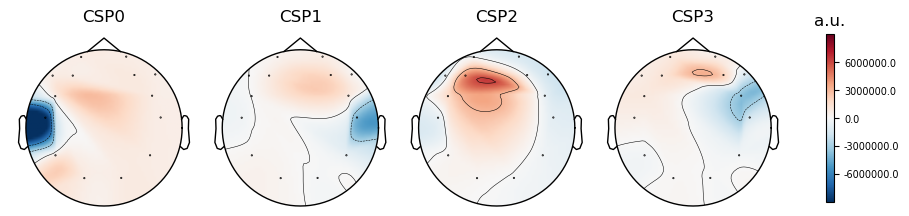

In [8]:
# Channel names follow the standard 10-20 system, so topomap plotting is supported
info = mne.create_info(ch_names, sfreq=fs, ch_types="eeg")
info.set_montage("standard_1020")

csp_vis = CSP(n_components=4, reg="ledoit_wolf", log=True, norm_trace=False, rank=CSP_RANK)
csp_vis.fit(X, y)

csp_vis.plot_patterns(info, components=range(4), ch_type="eeg", units="a.u.", size=1.5)
plt.show()

### CSP Feature Space

After applying CSP to each trial, we obtain a feature vector of log-variance (= log-power)
per component. The first and last components are designed to be most discriminative between
the two classes. Let's visualize the class distribution in a scatter plot.

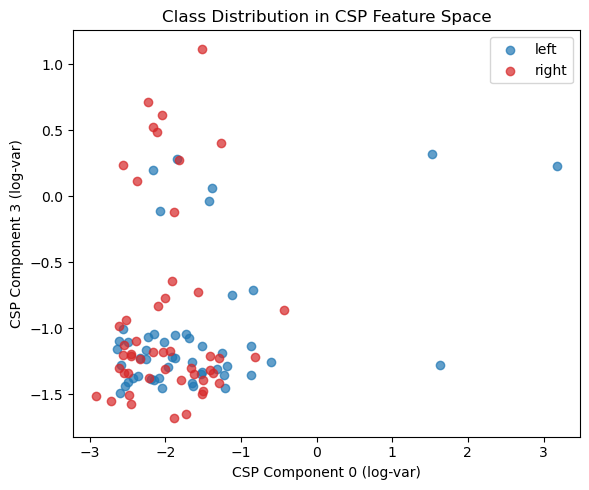

In [9]:
feat = csp_vis.transform(X)  # (n_trials, n_components)
fig, ax = plt.subplots(figsize=(6, 5))
for label, color in [(U.LABEL_LEFT, "tab:blue"), (U.LABEL_RIGHT, "tab:red")]:
    m = y == label
    ax.scatter(feat[m, 0], feat[m, -1], c=color, label=U.CLASS_NAMES[label], alpha=0.7)
ax.set(xlabel="CSP Component 0 (log-var)", ylabel="CSP Component 3 (log-var)",
       title="Class Distribution in CSP Feature Space")
ax.legend(); plt.tight_layout(); plt.show()

## 5. Cross-Validation with CSP + Classifier

We connect CSP and a classifier (LDA or SVM) in a `Pipeline` and measure accuracy
with cross-validation. **How we split the data into train/test matters:**

- All 5 sessions in this dataset were recorded **back-to-back in a single sitting**
  (same day, same cap placement — see the session timestamps in Section 1). The biggest
  source of EEG non-stationarity *between* sessions — taking the headset off and
  re-fitting it, impedance/skin changes, electrode drift across days — is therefore
  **absent** here.
- Each trial is **one independent 4-second MI epoch** (trials do not overlap in time),
  so placing different trials in train vs. test does not share any samples.
- ✅ For this single-day dataset we use **Stratified 5-fold cross-validation**: trials are
  split at random into 5 folds while keeping the left/right ratio balanced in each fold.

> 📅 **When your data spans multiple days/sessions, switch to Leave-One-Session-Out
> (LOSO) instead.** Across days, re-fitting the cap and physiological drift make each
> session its own distribution, and randomly mixing them would let "same-cap-placement"
> cues leak between train and test — overestimating accuracy. LOSO
> (`sklearn.model_selection.LeaveOneGroupOut` with `groups=ds.session`) holds out one
> whole session and measures the realistic *"does it work on a different day?"* generalization.

> CSP is re-fitted on each fold's **training data only** (the `Pipeline` handles this
> automatically), so no test data leaks into the spatial filter. This is separate from
> the visualization CSP fitted above.

In [10]:
# Stratified 5-fold: random split, but each fold keeps the left/right balance.
# (For multi-day data use LeaveOneGroupOut(groups=ds.session) instead — see note above.)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

pipelines = {
    "CSP + LDA": Pipeline([("csp", CSP(n_components=4, reg="ledoit_wolf", log=True, rank=CSP_RANK)), ("clf", LDA())]),
    "CSP + SVM": Pipeline([("csp", CSP(n_components=4, reg="ledoit_wolf", log=True, rank=CSP_RANK)),
                            ("clf", SVC(kernel="rbf", C=1.0))]),
}

# cross_validate fits each fold once and reports several metrics at the same time
# (cheaper than calling cross_val_score separately for accuracy and AUC).
for name, pipe in pipelines.items():
    cv = cross_validate(pipe, X, y, cv=skf,
                        scoring=["accuracy", "roc_auc"])
    acc, auc = cv["test_accuracy"], cv["test_roc_auc"]
    print(f"{name:12s} | acc {acc.mean():.3f}±{acc.std():.3f}"
          f" | AUC {auc.mean():.3f}±{auc.std():.3f}")

print("\n(Chance = 0.50. On a dataset this small, a mean slightly above 0.5 is not yet proof of\n"
      " real decoding — look at the ± spread: if it straddles 0.5, the result is within noise.)")

CSP + LDA    | acc 0.606±0.051 | AUC 0.630±0.075
CSP + SVM    | acc 0.545±0.033 | AUC 0.574±0.060

(Chance = 0.50. On a dataset this small, a mean slightly above 0.5 is not yet proof of
 real decoding — look at the ± spread: if it straddles 0.5, the result is within noise.)


### Confusion Matrix, AUC-ROC, and Cohen's κ

We aggregate the 5-fold cross-validation predictions from CSP + LDA to compute three evaluation metrics.

| Metric | Description | Chance level |
|---|---|---|
| **Accuracy** | Fraction of correctly classified trials | 0.50 |
| **AUC-ROC** | Separability based on probability scores (1.0 = perfect) | 0.50 |
| **Cohen's κ** | Chance-corrected agreement (0.0 = chance, 1.0 = perfect) | 0.0 |

κ interpretation: < 0.20 = slight, 0.20–0.40 = fair, 0.40–0.60 = moderate, ≥ 0.60 = good

CSP + LDA  |  acc=0.606  AUC=0.617  κ=0.212


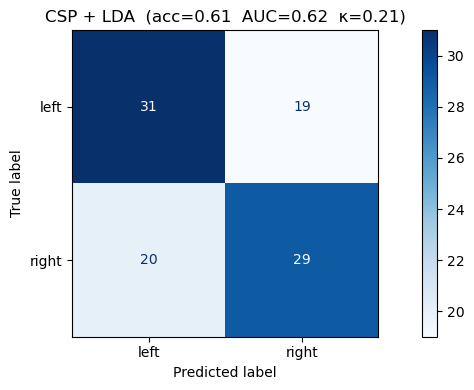

In [11]:
pipe = Pipeline([("csp", CSP(n_components=4, reg="ledoit_wolf", log=True, rank=CSP_RANK)), ("clf", LDA())])
# one CV pass gives the class probabilities; the hard label is just its argmax,
# so predictions and probabilities are guaranteed to agree.
y_proba = cross_val_predict(pipe, X, y, cv=skf, method="predict_proba")
y_pred  = y_proba.argmax(1)

acc   = (y_pred == y).mean()
auc   = roc_auc_score(y, y_proba[:, 1])
kappa = cohen_kappa_score(y, y_pred)
print(f"CSP + LDA  |  acc={acc:.3f}  AUC={auc:.3f}  κ={kappa:.3f}")

cm = confusion_matrix(y, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=[U.CLASS_NAMES[0], U.CLASS_NAMES[1]])
disp.plot(cmap="Blues", values_format="d")
plt.title(f"CSP + LDA  (acc={acc:.2f}  AUC={auc:.2f}  κ={kappa:.2f})")
plt.tight_layout(); plt.show()

## 6. Pushing Accuracy Further — Narrowing to the μ-band (8–13 Hz)

So far CSP used the full 8–30 Hz band. But ERD over the hand motor area is
**strongest in the μ-band (8–13 Hz)**; the higher β range often adds more noise than
signal. By restricting the bandpass to the μ-band *before* CSP, we sharpen the
left–right contrast the spatial filter has to work with.

We simply reload the data with a narrower bandpass and rerun the **same CSP + LDA
pipeline** — no new algorithm, just a better-targeted frequency range.

In [12]:
# Frequency range for this section. (8.0, 13.0) keeps only the μ-band;
# try (8.0, 30.0) to confirm the μ-band restriction is what helps.
MU_BAND_HZ = (8.0, 13.0)

# Reload every channel with the narrower μ-band bandpass, reusing the same
# bad-trial rejection as above.
ds_mu_original = U.load_dataset(
    data_dir=DATA_DIR, bandpass=MU_BAND_HZ, notch_hz=NOTCH_HZ, reference=REFERENCE
)
ds_mu = (U.remove_bad_trials(ds_mu_original, BAD_TRIALS)
         if REJECT_BAD_TRIALS else ds_mu_original)
y_mu = ds_mu.y
print(f"μ-band {MU_BAND_HZ} Hz, all {ds_mu.X.shape[1]} channels: {ds_mu.X.shape}")

# Same CSP + LDA pipeline as Section 5, now on μ-band data.
pipe_mu = Pipeline([("csp", CSP(n_components=4, reg="ledoit_wolf", log=True, rank=CSP_RANK)),
                    ("clf", LDA())])
y_proba_mu = cross_val_predict(pipe_mu, ds_mu.X, y_mu, cv=skf, method="predict_proba")
y_pred_mu  = y_proba_mu.argmax(1)
acc_mu   = (y_pred_mu == y_mu).mean()
auc_mu   = roc_auc_score(y_mu, y_proba_mu[:, 1])
kappa_mu = cohen_kappa_score(y_mu, y_pred_mu)
print(f"CSP + LDA (μ-band, all ch)  |  acc={acc_mu:.3f}  AUC={auc_mu:.3f}  κ={kappa_mu:.3f}")

μ-band (8.0, 13.0) Hz, all 14 channels: (99, 14, 512)


CSP + LDA (μ-band, all ch)  |  acc=0.677  AUC=0.657  κ=0.354


### Method Comparison Summary

Method                        Accuracy   AUC-ROC   Cohen κ
----------------------------------------------------------
CSP+LDA (8–30 Hz, all ch)        0.606     0.617     0.212
CSP+LDA (μ-band, all ch)         0.677     0.657     0.354


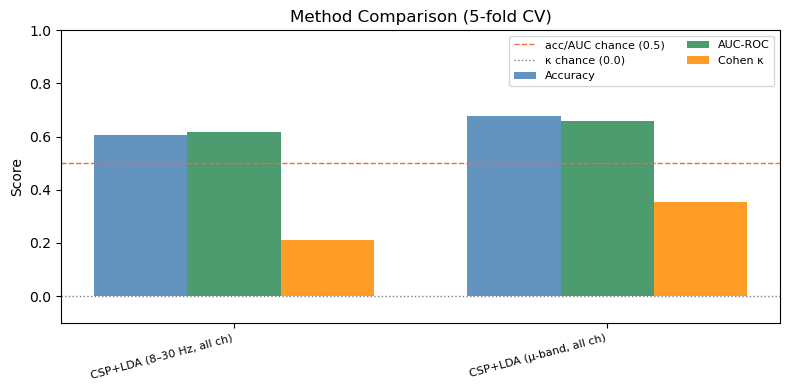

In [13]:
# Gather 5-fold CV predictions for each method and compare acc / AUC / κ
def eval_pipe(pipe, Xd, yd):
    # one CV pass: probabilities for AUC, and their argmax as the hard label
    yprob = cross_val_predict(pipe, Xd, yd, cv=skf, method="predict_proba")
    yp = yprob.argmax(1)
    return {
        "acc":   (yp == yd).mean(),
        "auc":   roc_auc_score(yd, yprob[:, 1]),
        "kappa": cohen_kappa_score(yd, yp),
    }

rows = {
    "CSP+LDA (8–30 Hz, all ch)": eval_pipe(
        Pipeline([("csp", CSP(n_components=4, reg="ledoit_wolf", log=True, rank=CSP_RANK)), ("clf", LDA())]),
        X, y),
    "CSP+LDA (μ-band, all ch)": eval_pipe(
        Pipeline([("csp", CSP(n_components=4, reg="ledoit_wolf", log=True, rank=CSP_RANK)), ("clf", LDA())]),
        ds_mu.X, y_mu),
}

print(f"{'Method':<28} {'Accuracy':>9} {'AUC-ROC':>9} {'Cohen κ':>9}")
print("-" * 58)
for name, m in rows.items():
    print(f"{name:<28} {m['acc']:>9.3f} {m['auc']:>9.3f} {m['kappa']:>9.3f}")

# Bar chart comparing all three metrics
df = pd.DataFrame(rows).T
x = np.arange(len(df))
w = 0.25
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - w, df["acc"],   w, label="Accuracy", color="steelblue",  alpha=0.85)
ax.bar(x,     df["auc"],   w, label="AUC-ROC",  color="seagreen",   alpha=0.85)
ax.bar(x + w, df["kappa"], w, label="Cohen κ",  color="darkorange",  alpha=0.85)
ax.axhline(0.5, color="tomato", ls="--", lw=1, label="acc/AUC chance (0.5)")
ax.axhline(0.0, color="gray",   ls=":",  lw=1, label="κ chance (0.0)")
ax.set_xticks(x); ax.set_xticklabels(df.index, rotation=15, ha="right", fontsize=8)
ax.set(ylabel="Score", title="Method Comparison (5-fold CV)", ylim=(-0.1, 1.0))
ax.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()

## 7. Summary and Exercises

**What we learned** (single-day dataset, Stratified 5-fold CV; exact numbers vary slightly with the random split)

| Method | Accuracy | AUC-ROC | Key takeaway |
|---|---|---|---|
| CSP + LDA (8–30 Hz, all 14ch) | ~0.61 | ~0.62 | Baseline |
| CSP + LDA (μ-band, all 14ch) | ~0.68 | ~0.66 | Narrowing to the μ-band helps most |

- **μ-band (8–13 Hz)** carries the main ERD signal; restricting the bandpass to it gives
  the biggest single jump. β effectiveness varies by person.
- A good **frequency range often matters more than a fancier classifier** — the *same*
  CSP + LDA improves simply by feeding it a better-targeted band.
- Accuracy plateaus around 0.65–0.68: MI decoding without C3/C4 electrodes (EPOC X)
  is inherently hard — electrode placement and data volume are the dominant bottlenecks,
  regardless of algorithm. On a dataset this small, treat small accuracy gaps as noise.

> ⚠️ These scores use **5-fold CV because all sessions are same-day**. With multi-day data,
> evaluate with LOSO (Section 5 note); cross-day scores are typically **lower**, since the
> model must also survive cap re-placement and physiological drift.

**Exercises (try these)**
1. Change `MU_BAND_HZ` to `(8.0, 30.0)` or `(13.0, 30.0)`. Which band decodes best?
2. Swap `LDA()` for `SVC(kernel="rbf")` in the μ-band pipeline. Does it help?
3. Change `n_components` in CSP (e.g. 2, 6, 8). How does it affect accuracy?
4. Compare this CSP + LDA accuracy with EEGNet accuracy from Notebook ②.